# Publications over the years

- Data processing for this particular study: we save the publications per years in different files, in data/processed.
- Plot area chart of the publications over the years, for different topics.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import itertools
from collections import Counter
import matplotlib.cm as cm
import matplotlib.ticker as ticker

# Base paths for data
DATA = Path("../data")
EXTERNAL = DATA / "external"
PROCESSED = DATA / "processed" / "per_years"
PROCESSED.mkdir(parents=True, exist_ok=True) # create folders if they don't exist

In [ ]:
# CVD-safe palette
colors = {'Social': '#0072B2','Physics': '#E69F00','Life':   '#009E73','Health':    '#CC79A7'} # COLORS ADRI
#colors = [cm.viridis(x) for x in np.linspace(0.1, 0.9, 4)]
#colors = ['#482878', '#31688e', '#35b779', '#fde725'] PER SI DE CAS NO VA

# HEALTH SCIENCE: purple
# PHYSICAL SCIENCES: blue
# LIFE SCIENCES: turquoise
# SOCIAL SCIENCES: yellow

### PRIMARY FILE: papers_cleaned.gencat.parquet

In [5]:
# DATASET: papers_cleaned.gencat.parquet
# Source: Dades obertes de la Generalitat de Catalunya
# Description: cleaned catalan publications
file_path = EXTERNAL / "papers_cleaned.gencat.parquet"

### Load data

In [6]:
def load_local_parquet(path):
    """Carrega un fitxer parquet local."""
    if not path.exists():
        raise FileNotFoundError(f"No s'ha trobat el fitxer: {path}")
    return pd.read_parquet(path)

# Load our data from dataset 'papers_cleaned.gencat.parquet'
df = load_local_parquet(file_path)
print(f"Carregades {len(df)} files.")

Carregades 1747707 files.


### Checks (and exploration)
We do a check and explore the columns/raws we have in our data

In [7]:
def profile(df):
    "To avoid error in the cells where there are lists (authors), we convert them into string"
    df_temp = df.copy()
    # Convert all the columns into strings (to avoid errors in lists, arrays...)
    for col in df_temp.columns:
        try:
            df_temp[col] = df_temp[col].astype(str)
        except Exception:
            pass
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (100 * df.isna().mean()).round(1),
        "n_unique": df_temp.nunique(),
    })

# Print data profile
display(profile(df))
# Print the first raws to explore the data we have
display(df.head())

,dtype,n_missing,pct_missing,n_unique
date,object,0,0.0,11123
doi,object,0,0.0,358039
ruct,object,0,0.0,88888
orcidResearchers,object,0,0.0,824070
orcidUncheckedAuthors,object,1623199,92.9,15920
orcidDirectors,object,1744810,99.8,64


,date,doi,ruct,orcidResearchers,orcidUncheckedAuthors,orcidDirectors
0,1949-01-01T00:00:00.000,10.1210/jcem-9-9-883,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
1,1952-01-01T00:00:00.000,10.1002/cber.19520850704,Universitat Rovira i Virgili,[0000-0001-6112-5913],None,None
2,1952-01-01T00:00:00.000,10.1111/j.1365-2133.1952.tb15900.x,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
3,1953-01-01T00:00:00.000,10.1038/jid.1953.55,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
4,1954-01-01T00:00:00.000,10.1016/s0022-5347(17)67795-4,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None


### Data processing

We separate all the publications in different files per years, and we conserve the following columns: date, DOI.

In [14]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# Order years
anys_disponibles = sorted(df['year'].unique())

# Loop to create folders and files per year
for any_pub in anys_disponibles:

    # Filter the rows of this year
    df_any = df[df['year'] == any_pub]

    # Create and save file
    nom_fitxer = f"{any_pub}_publications.parquet"
    ruta_final = PROCESSED / nom_fitxer
    df_any.to_parquet(ruta_final, index=False)
    print(f"Desat: {nom_fitxer} ({len(df_any)} files)")

print(f"\nFet! S'han creat {len(anys_disponibles)} fitxers a la carpeta '{PROCESSED.resolve()}'.")

Desat: 1949_publications.parquet (1 files)
Desat: 1952_publications.parquet (2 files)
Desat: 1953_publications.parquet (1 files)
Desat: 1954_publications.parquet (2 files)
Desat: 1956_publications.parquet (1 files)
Desat: 1957_publications.parquet (1 files)
Desat: 1959_publications.parquet (1 files)
Desat: 1961_publications.parquet (2 files)
Desat: 1962_publications.parquet (3 files)
Desat: 1964_publications.parquet (1 files)
Desat: 1966_publications.parquet (1 files)
Desat: 1967_publications.parquet (1 files)
Desat: 1969_publications.parquet (6 files)
Desat: 1970_publications.parquet (36 files)
Desat: 1972_publications.parquet (7 files)
Desat: 1973_publications.parquet (14 files)
Desat: 1974_publications.parquet (19 files)
Desat: 1975_publications.parquet (18 files)
Desat: 1976_publications.parquet (26 files)
Desat: 1977_publications.parquet (41 files)
Desat: 1978_publications.parquet (51 files)
Desat: 1979_publications.parquet (87 files)
Desat: 1980_publications.parquet (126 files)
D

### PLOT 1: all publications over the years

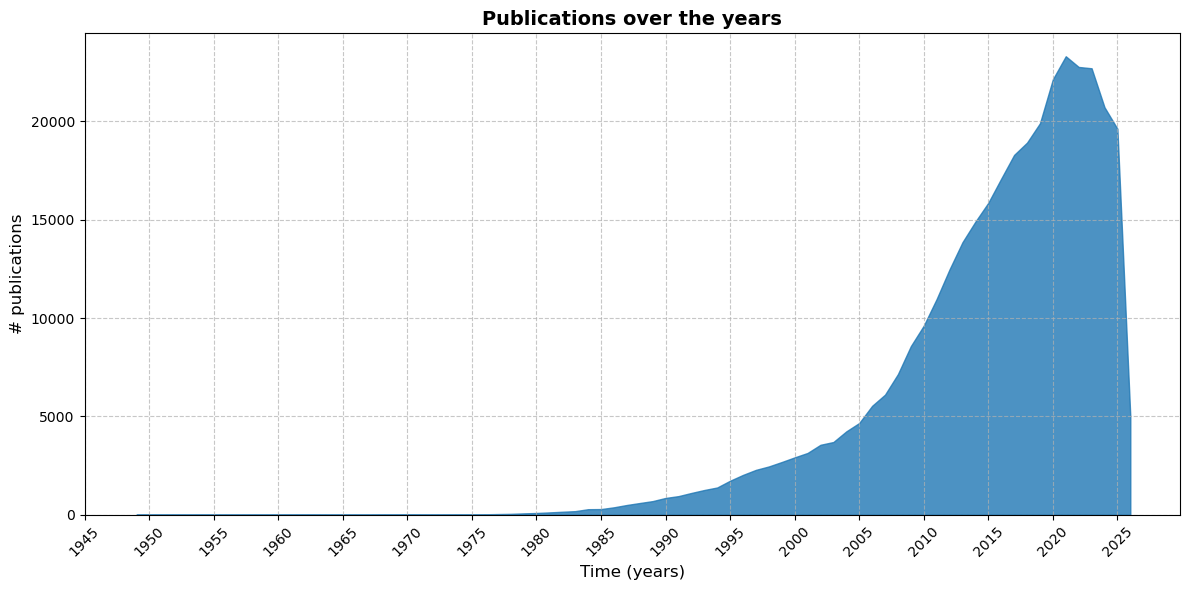

In [9]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# FILTER DUPLICATED DOIS-----------------------------------------------
df_unics = df.drop_duplicates(subset=["doi"])
#----------------------------------------------------------------------

# Counts publications per year
publicacions_per_any = df_unics['year'].value_counts().sort_index()

anys = publicacions_per_any.index
quantitat = publicacions_per_any.values

# PLOT
plt.figure(figsize=(12, 6))
plt.stackplot(anys, quantitat, labels=['Total publicacions'], color='#1f77b4', alpha=0.8)
plt.title("Publications over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("# publications", fontsize=12)
ticks_anys = np.arange(1945, max(anys) + 1, 5)
plt.xticks(ticks_anys, rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
#plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

### SECONDARY FILES: fields.parquet, works.parquet

In [10]:
# FIELDS (fields.parquet)

fields_df = pd.read_parquet("../data/external/fields.parquet")

print("Columnes:", fields_df.columns.tolist())
print(f"Dimensions: {fields_df.shape[0]} files i {fields_df.shape[1]} columnes")

#display(fields_df.head()) # shows firsts raws
display(fields_df) # shows all raws 26)

Columnes: ['field_id', 'field_name', 'domain_id', 'domain_name']
Dimensions: 26 files i 4 columnes


,field_id,field_name,domain_id,domain_name
0,33,Social Sciences,2,Social Sciences
1,31,Physics and Astronomy,3,Physical Sciences
2,27,Medicine,4,Health Sciences
3,12,Arts and Humanities,2,Social Sciences
4,11,Agricultural and Biological Sciences,1,Life Sciences
5,22,Engineering,3,Physical Sciences
6,17,Computer Science,3,Physical Sciences
7,23,Environmental Science,3,Physical Sciences
8,14,"Business, Management and Accounting",2,Social Sciences
9,13,"Biochemistry, Genetics and Molecular Biology",1,Life Sciences


In [23]:
# WORKS (works.parquet)

works_df = pd.read_parquet("../data/external/works.parquet")

print(f"Dimensions: {works_df.shape[0]} files, {works_df.shape[1]} columnes")
print("Columnes:", works_df.columns.tolist())

display(works_df.head(2))

Dimensions: 348417 files, 9 columnes
Columnes: ['openalex_id', 'doi', 'apc_paid_value_usd', 'apc_list_value_usd', 'awards', 'funders', 'primary_topic_field_id', 'topics_field_ids', 'referenced_works']


,openalex_id,doi,apc_paid_value_usd,apc_list_value_usd,awards,funders,primary_topic_field_id,topics_field_ids,referenced_works
0,W2052543964,10.1021/ja01036a083,NaN,4500.0,[],[],16,[],[]
1,W2917211058,10.1016/j.patrec.2019.02.029,NaN,2550.0,[],[],17,[],[]


### Cross data

In [80]:
PROCESSED = Path("../data/processed")
PER_YEARS = PROCESSED / "per_years"

# Join all files per years in one temporary variable called df_total
llista_dfs = [pd.read_parquet(f) for f in PER_YEARS.glob("*_publications.parquet")]
df_total = pd.concat(llista_dfs, ignore_index=True)

# FILTER DUPLICATED DOIS-----------------------------------------------
total_files_originals = len(df_total)
dois_unics_originals = df_total["doi"].nunique()
duplicats_originals = total_files_originals - dois_unics_originals

print(f"Files originals: {total_files_originals}")
print(f"DOIs únics: {dois_unics_originals}")
print(f"Duplicats detectats a l'origen: {duplicats_originals}")
# ---------------------------------------------------------------------

df_total_unics = df_total.drop_duplicates(subset=["doi"])
print("Dois unics drop duplicates", len(df_total_unics))

# Load data (fields, domains..)
works = pd.read_parquet("../data/external/works.parquet", columns=["doi", "primary_topic_field_id", "topics_field_ids"])
fields = pd.read_parquet("../data/external/fields.parquet")

work_temporal = works.drop_duplicates(subset=["doi"])
total_works_temporal = len(work_temporal)
print("TOTAL WORKS",len(works))
print("Total NO DUPLICATS de works:",total_works_temporal)
print("Duplicats works",len(works)-total_works_temporal)

# Force that IDs are text to merge them correctly
works["primary_topic_field_id"] = works["primary_topic_field_id"].astype(str)
fields["field_id"] = fields["field_id"].astype(str)

# Create diccionaries to traduce IDs into names
field_to_domain = dict(zip(fields["field_id"], fields["domain_name"]))
field_to_name = dict(zip(fields["field_id"], fields["field_name"]))

# Merge works to the df_total (doi,date)
df_complet = df_total_unics.merge(work_temporal, on="doi", how="left",validate="one_to_one") # merge 'left' to conserve all papers
print("TOTAL MERGED:", len(df_complet))

Files originals: 1747707
DOIs únics: 358039
Duplicats detectats a l'origen: 1389668
Dois unics drop duplicates 358039
TOTAL WORKS 348417
Total NO DUPLICATS de works: 347999
Duplicats works 418
TOTAL MERGED: 358039


In [79]:
# Add domains and topics names
df_complet["domain_name"] = df_complet["primary_topic_field_id"].map(field_to_domain)
df_complet["field_name"] = df_complet["primary_topic_field_id"].map(field_to_name)

# Select only the columns we want
columnes_finals = ["year", "doi", "domain_name", "field_name", "topics_field_ids"]
df_final = df_complet[columnes_finals]

# Save the file: all_publications_enriched.parquet
output_path = PROCESSED / "all_publications_enriched_new.parquet"
df_final.to_parquet(output_path, index=False)

print(f"Dimensions: {df_final.shape[0]} files, {df_final.shape[1]} columnes")
print(f"Columnes: {df_final.columns.tolist()}")

# Count papers with and without topic and print nums
total_papers = len(df_final)
papers_sense_topic = df_final["domain_name"].isna().sum()
papers_amb_topic = total_papers - papers_sense_topic

print(f"Total de papers (sense tocar res): {total_papers}")
print(f"Papers SENSE topic assignat: {papers_sense_topic}")
print(f"Papers AMB topic assignat: {papers_amb_topic}")
print(f"Percentatge de papers sense topic: {(papers_sense_topic / total_papers) * 100:.2f}%")

Dimensions: 358039 files, 5 columnes
Columnes: ['year', 'doi', 'domain_name', 'field_name', 'topics_field_ids']
Total de papers (sense tocar res): 358039
Papers SENSE topic assignat: 12313
Papers AMB topic assignat: 345726
Percentatge de papers sense topic: 3.44%


COSES A FER:
- amb el grafic darees, veig una explosio de publicacions i vull saber com es aquest creixement exponencial  (--> faig log log per caracteritzarho). també veig que cap al 2020 hi ha un canvi altre creixement (--> miro per mesos exactament què passa) --> per veure millor, faig un requadre a efectes covid?
- amb el grafic log log trec els efectes de l'escala (ferho amb punts per pintar els que faig servir per a la regressio i recta regressio en vermell flotant a dalt) --> equacio exp(coef*x^alfa) --> he de trobar lalfa per saber quin es el creixement que té i amb el coef ajusto com d'amunt poso la recta. també puc veure lexces en el moment del covid.
- amb el grafic del covid (2019,2020,2021,2022) faig un estudi (avanç dels domains?) i faig una casella al lockdown. al covid també puc mirar com evolucionen les àrees que més shi relacionaven (psico,medicina...) 
- documentarme si a partir del 2024 realment encara no estan publicats els papers (mirar a la web generalitat)

LLEGENDA:
- gràfic log --> e^x (creixement exponencial)
- gràfic log-log --> e^(x^alfa) (llei de potències)

### PLOT 2: Publications over the years per domain

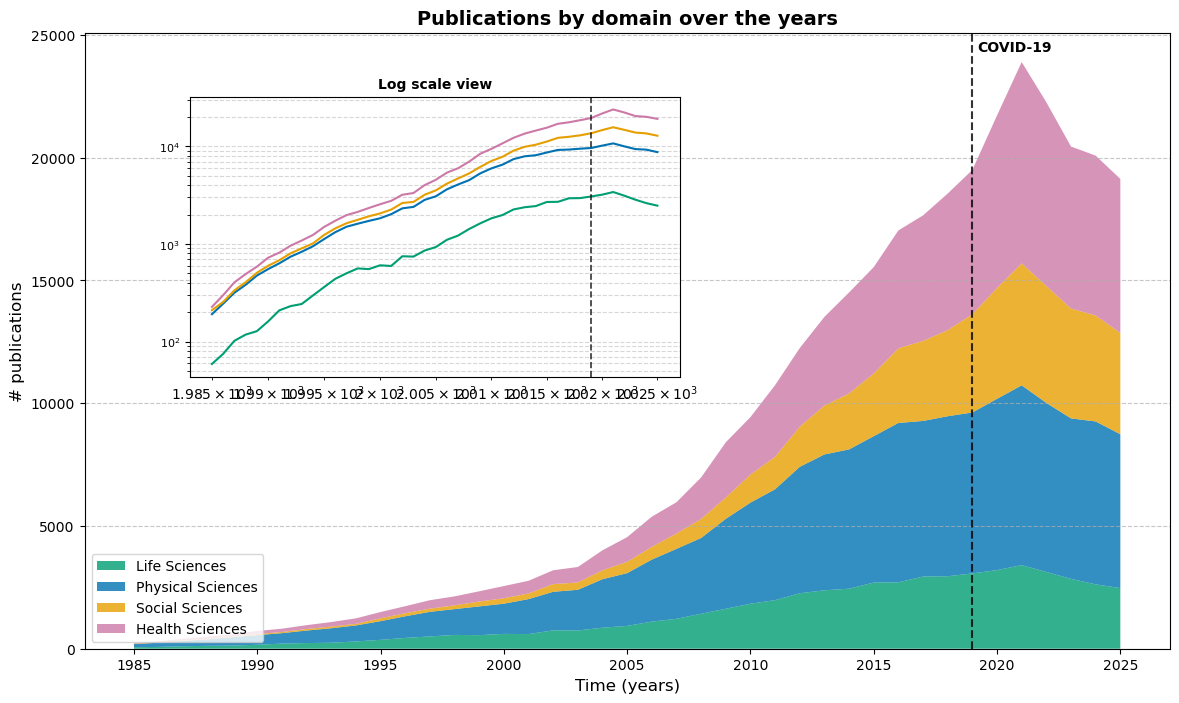

In [94]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}
# Only papers with domain assigned
df_plots = df.dropna(subset=["domain_name"])

# Eliminate DOI duplicated publications
#df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

# Create table for the plot: Files = Anys, Columnes = Dominis, Valors = Nombre de papers
taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order] # Apliquem l'ordre a les columnes

# FILTER THE YEARS AFTER 1980 and BEFORE 2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()

colors_list = [colors[col] for col in etiquetes]

cumsum = taula_dominis.cumsum(axis=1)

# PLOT
#plt.figure(figsize=(12, 6))
#plt.stackplot(anys, quantitats, labels=etiquetes, alpha=0.8)
#plt.title("Publications by domain over the years per domains", fontsize=14, fontweight='bold')
#plt.xlabel("Time (years)", fontsize=12)
#plt.ylabel("# publications", fontsize=12)
#plt.grid(axis='y', linestyle='--', alpha=0.7)
#plt.legend(loc='upper left') # Aquí sí que posem la llegenda perquè hi ha 4 colors!
#plt.tight_layout()

# PLOT
fig = plt.figure(figsize=(14, 8)) # He fet la figura una mica més gran
ax_main = fig.add_subplot(111)   # Aquest serà el gràfic gran
ax_main.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (years)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='lower left')

# Line to indicate COVID-19
ax_main.axvline(x=2019, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
ax_main.text(2019.2, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# Inset
ax_inset = fig.add_axes([0.2, 0.45, 0.35, 0.35]) 
for i, col in enumerate(cumsum.columns):
    ax_inset.plot(anys, cumsum[col], color=colors_list[i], linewidth=1.5)
ax_inset.set_yscale('log')
ax_inset.set_xscale('log')
ax_inset.set_title("Log scale view", fontsize=10, fontweight='bold')
ax_inset.grid(axis="y", linestyle='--', alpha=0.5, which='both') # 'both' inclou les línies de la graella logarítmica
ax_inset.tick_params(axis='both', labelsize=8)
# Line to indicate COVID-19 in the inset
ax_inset.axvline(x=2019, color='black', linestyle='--', linewidth=1.2, alpha=0.8)

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/area_chart_publications_by_domain.png", dpi=300, bbox_inches='tight')

plt.show()

Linear regression has been generated by the python function, and according to the TOTAL of publications (upper line, because it is the total sum of all domains). The data used for the regression are the marked points.

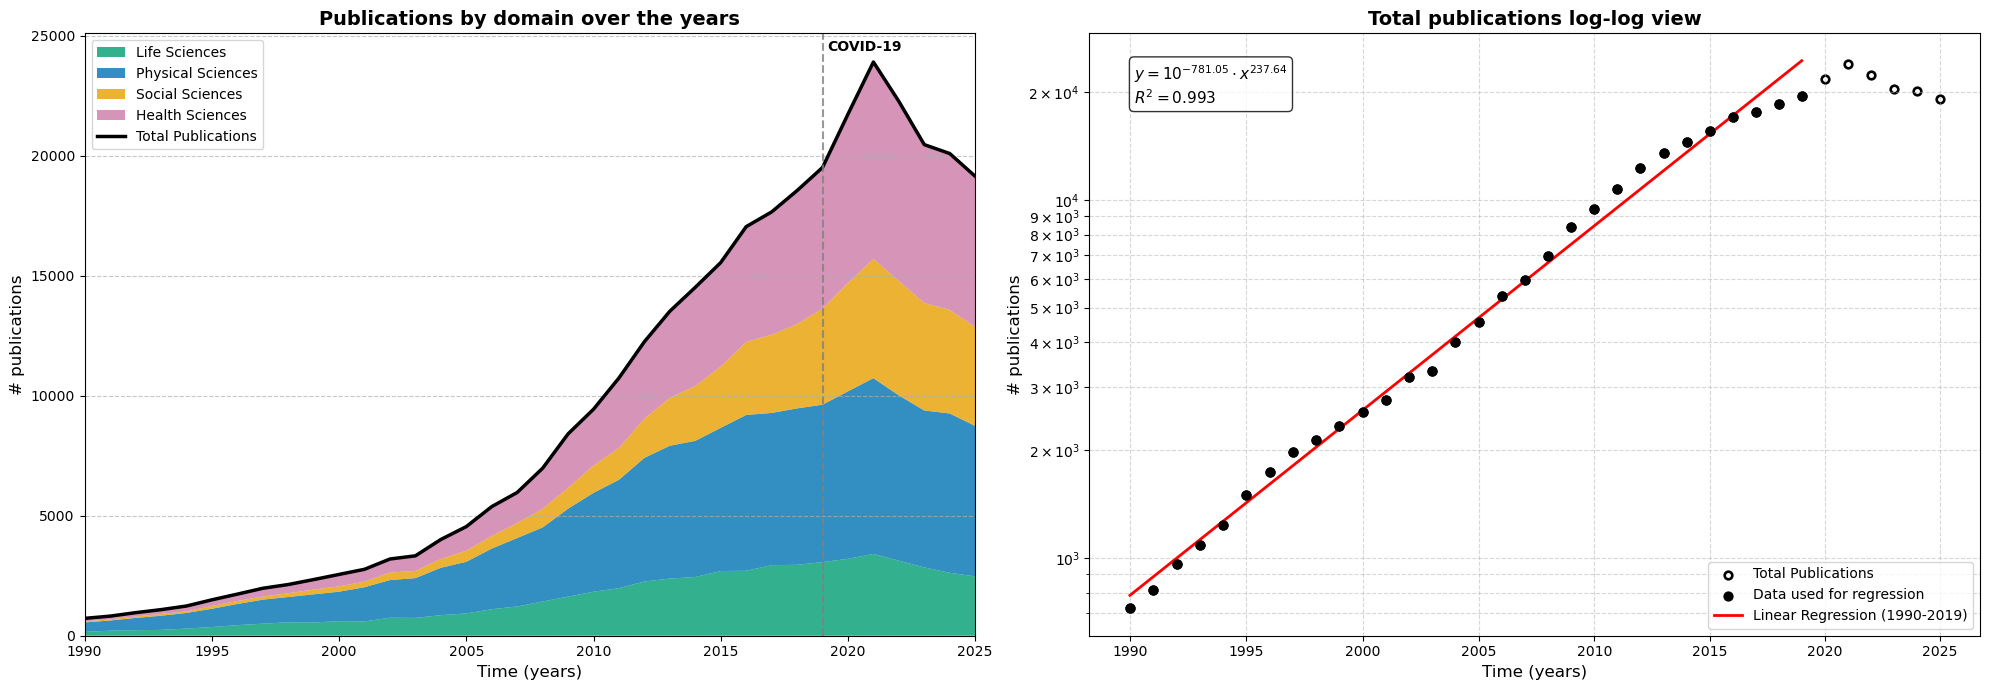

In [8]:
df = pd.read_parquet("../data/processed/all_publications_enriched_new.parquet")
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}
df_plots = df.dropna(subset=["domain_name"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]
taula_dominis = taula_dominis[(taula_dominis.index >= 1990) & (taula_dominis.index <= 2025)]

anys = taula_dominis.index
quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()
colors_list = [colors[col] for col in etiquetes]

# Total publications per year
total_per_any = taula_dominis.sum(axis=1)
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(20, 7))

# PLOT LEFT-------------------------------------------------------------------------
ax_left.stackplot(anys, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
line_total, = ax_left.plot(anys, total_per_any, color='#000000', linewidth=2.5, label='Total Publications')
## ax_left.plot(anys, total_per_any, color='#000000', linewidth=2.5, label='Total Publications')
ax_left.set_title("Publications by domain over the years", fontsize=14, fontweight='bold')
ax_left.set_xlabel("Time (years)", fontsize=12)
ax_left.set_ylabel("# publications", fontsize=12)
ax_left.grid(axis='y', linestyle='--', alpha=0.7)
ax_left.set_xlim(anys.min(), anys.max())

# Manual legend to introduce total of publications
handles, labels = ax_left.get_legend_handles_labels()
handles.append(line_total)
labels.append('Total Publications')

## ax_left.legend(handles=handles, labels=labels, loc='upper left')
ax_left.legend(loc='upper left')
ax_left.axvline(x=2019, color='gray', linestyle='--', linewidth=1.5, alpha=0.8)
ax_left.text(2019.2, ax_left.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')

# PLOT RIGHT------------------------------------------------------------------------
ax_right.scatter(anys, total_per_any, color='white',edgecolor='#000000',linewidth=1.9, s=30, label='Total Publications')

# LINEAR REGRESSION from 1990 fins tp 2019
mask = (anys >= 1990) & (anys <= 2019)
anys_reg = anys[mask]
total_reg = total_per_any[mask]

#ax_right.scatter(anys[mask], total_per_any[mask], color='red', s=40, edgecolor='white', zorder=3, label='Data used for regression')
ax_right.scatter(anys[mask], total_per_any[mask], color='#000000', edgecolor='#000000', linewidths=1.9, s=30, zorder=3, label='Data used for regression')

log_anys = np.log10(anys_reg) # Linear regression: log(y) = m * log(x) + b, so we adapt that
log_total = np.log10(total_reg)

# Fit (m and b calculus)
m, b = np.polyfit(log_anys, log_total, 1)

# R^2 calculus
total_pred = m * log_anys + b
ss_res = np.sum((log_total - total_pred) ** 2)
ss_tot = np.sum((log_total - np.mean(log_total)) ** 2)
r_squared = 1 - (ss_res / ss_tot)

# Linear regression
x_fit = np.linspace(min(log_anys), max(log_anys), 100)
y_fit = m * x_fit + b
ax_right.plot(10**x_fit, 10**y_fit, color='red', linewidth=2, label='Linear Regression (1990-2019)')
#text_eq = "$y = 10^{" + f"{b:.2f}" + " \\cdot x^{" + f"{m:.2f}" + "} }$\n" + "$R^2 = " + f"{r_squared:.3f}" + "$"
text_eq = f"$y = 10^{{{b:.2f}}} \\cdot x^{{{m:.2f}}}$\n$R^2 = {r_squared:.3f}$"
ax_right.text(0.05, 0.95, text_eq, transform=ax_right.transAxes, fontsize=11,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax_right.set_xscale('log')
ax_right.set_yscale('log')
ax_right.set_title("Total publications log-log view", fontsize=14, fontweight='bold')
ax_right.set_xlabel("Time (years)", fontsize=12)
ax_right.set_ylabel("# publications", fontsize=12)

anys_x = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
ax_right.set_xticks(anys_x)
ax_right.set_xticklabels(anys_x)
valors_y = [1e3, 2e3, 3e3, 4e3, 5e3, 6e3, 7e3, 8e3, 9e3, 1e4, 2e4]
etiquetes_y = [r'$10^3$', 
    r'$2 \times 10^3$', 
    r'$3 \times 10^3$', 
    r'$4 \times 10^3$', 
    r'$5 \times 10^3$', 
    r'$6 \times 10^3$', 
    r'$7 \times 10^3$', 
    r'$8 \times 10^3$', 
    r'$9 \times 10^3$', 
    r'$10^4$', 
    r'$2 \times 10^4$']
ax_right.set_yticks(valors_y)
ax_right.set_yticklabels(etiquetes_y)

ax_right.grid(True, linestyle='--', alpha=0.5, which='both')
ax_right.legend(loc='lower right')
plt.tight_layout()

# Save plots
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/publications_comparison_with_regression.png", dpi=300, bbox_inches='tight')

plt.show()

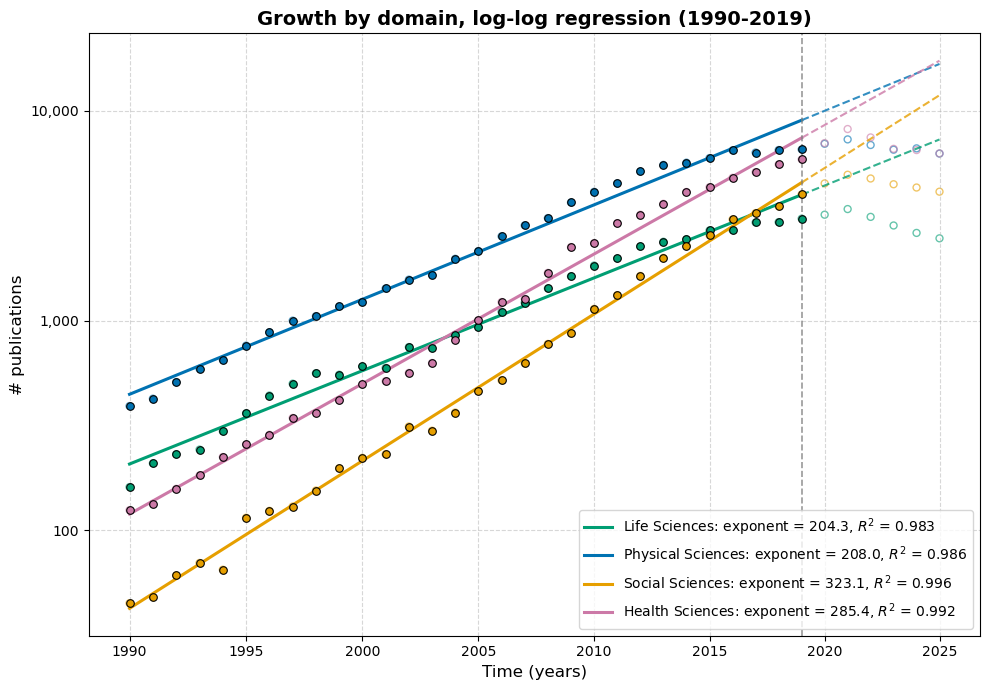

                      slope      R2  growth_%/yr  doubling_years
domain                                                          
Life Sciences      204.3488  0.9826          NaN             NaN
Physical Sciences  208.0010  0.9856          NaN             NaN
Social Sciences    323.0962  0.9957          NaN             NaN
Health Sciences    285.4375  0.9923          NaN             NaN

Total (sum of domains):      slope = 237.6417, R2 = 0.993
Unweighted mean of domains:  slope = 255.2209
Share-weighted mean:         slope = 244.1637


In [9]:
# Third plot: one regression per domain (not the stacked area, not the total).
# Uses `taula_dominis` (index = year, columns = domains) and `colors` from the notebook.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---- settings -------------------------------------------------------------
LOGLOG = True          # False: semi-log (log y vs year) -> exponential growth
                        # True : log-log  (log y vs log year) -> same as the right-hand plot
YEAR_MIN, YEAR_MAX = 1990, 2019   # fit window (pre-COVID)
YEAR_END = 2025                   # dashed extrapolation up to here
OUTPUT_DIR = "../plots/alba"
# ---------------------------------------------------------------------------


def fit_loglinear(years, counts, loglog=False):
    """Least squares on log10(counts) vs year (or vs log10(year)). Returns m, b, R^2."""
    years = np.asarray(years, dtype=float)
    counts = np.asarray(counts, dtype=float)
    ok = counts > 0
    x = np.log10(years[ok]) if loglog else years[ok]
    y = np.log10(counts[ok])
    m, b = np.polyfit(x, y, 1)
    pred = m * x + b
    r2 = 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)
    return m, b, r2


def predict(years, m, b, loglog=False):
    years = np.asarray(years, dtype=float)
    x = np.log10(years) if loglog else years
    return 10 ** (m * x + b)


def label_text(name, m, r2, loglog):
    if loglog:
        return f"{name}: exponent = {m:.1f}, $R^2$ = {r2:.3f}"
    growth = (10 ** m - 1) * 100            # % per year
    return f"{name}: +{growth:.1f}%/yr, $R^2$ = {r2:.3f}"


fit_df = taula_dominis[(taula_dominis.index >= YEAR_MIN) & (taula_dominis.index <= YEAR_MAX)]
total_fit = fit_df.sum(axis=1)

fig, ax = plt.subplots(figsize=(10, 7))
rows = []

for domain in taula_dominis.columns:
    col = colors[domain]
    years_all = taula_dominis.index.values
    counts_all = taula_dominis[domain].values

    # all observed points (hollow = not used in the fit)
    ax.scatter(years_all, counts_all, s=25, facecolors="none", edgecolors=col, alpha=0.6)

    # points used in the fit (filled)
    m, b, r2 = fit_loglinear(fit_df.index, fit_df[domain], LOGLOG)
    ax.scatter(fit_df.index, fit_df[domain], s=30, color=col, edgecolor="black",
               linewidths=0.8, zorder=3)

    # fitted line (solid) + extrapolation (dashed)
    y_fit = np.arange(YEAR_MIN, YEAR_MAX + 1)
    y_ext = np.arange(YEAR_MAX, YEAR_END + 1)
    ax.plot(y_fit, predict(y_fit, m, b, LOGLOG), color=col, lw=2.2,
            label=label_text(domain, m, r2, LOGLOG))
    ax.plot(y_ext, predict(y_ext, m, b, LOGLOG), color=col, lw=1.5, ls="--", alpha=0.8)

    rows.append({"domain": domain, "slope": m, "R2": r2,
                 "growth_%/yr": (10 ** m - 1) * 100 if not LOGLOG else np.nan,
                 "doubling_years": np.log10(2) / m if not LOGLOG else np.nan})

ax.axvline(YEAR_MAX, color="gray", ls="--", lw=1.2, alpha=0.8)
ax.set_yscale("log")
if LOGLOG:
    ax.set_xscale("log")
    ticks = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks)
    ax.minorticks_off()
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("# publications", fontsize=12)
ax.set_title(f"Growth by domain, {'log-log' if LOGLOG else 'semi-log'} regression "
             f"({YEAR_MIN}-{YEAR_MAX})", fontsize=14, fontweight="bold")
ax.grid(True, ls="--", alpha=0.5, which="both")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()

os.makedirs(OUTPUT_DIR, exist_ok=True)
plt.savefig(f"{OUTPUT_DIR}/publications_regression_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()

# ---- summary + answer to "is mean of domain growth == total growth?" ------
summary = pd.DataFrame(rows).set_index("domain")
m_tot, _, r2_tot = fit_loglinear(fit_df.index, total_fit, LOGLOG)
print(summary.round(4))
print(f"\nTotal (sum of domains):      slope = {m_tot:.4f}, R2 = {r2_tot:.3f}")
print(f"Unweighted mean of domains:  slope = {summary['slope'].mean():.4f}")
shares = fit_df.sum() / fit_df.sum().sum()
print(f"Share-weighted mean:         slope = {(summary['slope'] * shares).sum():.4f}")

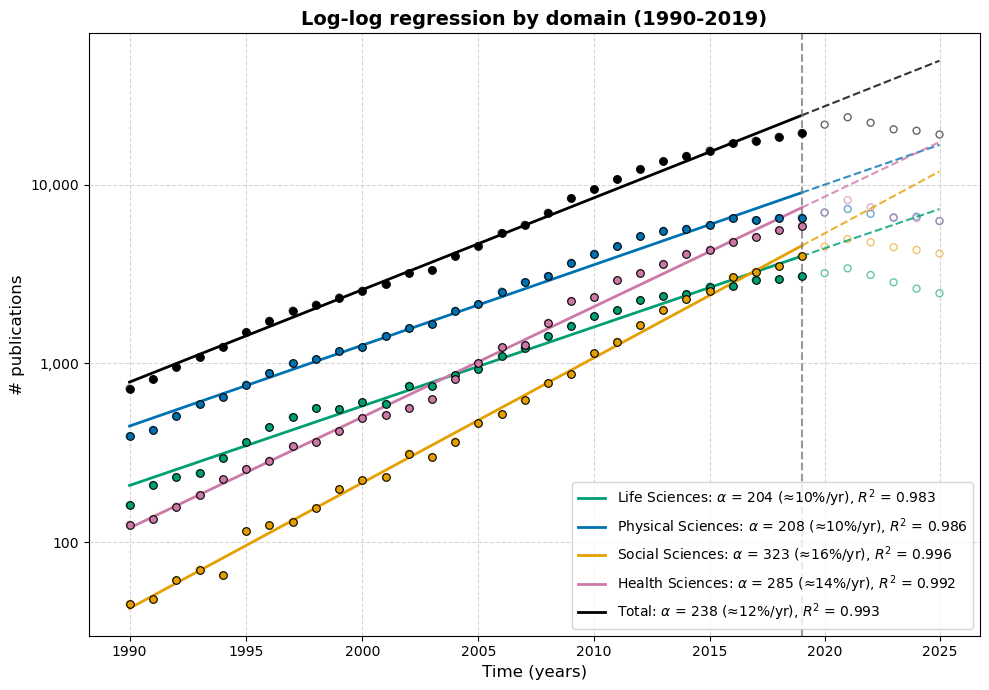

              domain    alpha  growth_%/yr     R2
0      Life Sciences  204.349       10.195  0.983
1  Physical Sciences  208.001       10.377  0.986
2    Social Sciences  323.096       16.119  0.996
3    Health Sciences  285.437       14.240  0.992
4              Total  237.642       11.855  0.993


In [ ]:
# LOG-LOG REGRESSION + TOTAL (1990-2019)
anys = taula_dominis.index
mask = (anys >= 1990) & (anys <= 2019)
anys_reg = anys[mask]

taula_total = taula_dominis.copy()
taula_total["Total"] = taula_dominis.sum(axis=1)
colors_tot = {**colors, "Total": "#000000"}

fig, ax = plt.subplots(figsize=(10, 7))
resultats = []

for col in taula_total.columns:
    # Punts: plens = usats a la regressió, buits = fora (2020-2025)
    ax.scatter(anys, taula_total[col], s=25, facecolors="none", edgecolors=colors_tot[col], alpha=0.6)
    ax.scatter(anys_reg, taula_total.loc[mask, col], s=30, color=colors_tot[col], edgecolor="#000000", linewidths=0.8, zorder=3)

    # Ajust: log(y) = alpha * log(x) + b
    log_x = np.log10(anys_reg)
    log_y = np.log10(taula_total.loc[mask, col])
    alpha, b = np.polyfit(log_x, log_y, 1)
    r2 = 1 - np.sum((log_y - (alpha * log_x + b)) ** 2) / np.sum((log_y - log_y.mean()) ** 2)
    creixement = alpha / np.mean(anys_reg) * 100  # creixement relatiu aprox. per any (%)
    resultats.append([col, alpha, creixement, r2])

    # Recta ajustada (contínua) i extrapolació fins al 2025 (discontínua)
    x_fit = np.linspace(1990, 2019, 100)
    x_ext = np.linspace(2019, 2025, 20)
    ax.plot(x_fit, 10 ** (alpha * np.log10(x_fit) + b), color=colors_tot[col], linewidth=2,
            label=f"{col}: $\\alpha$ = {alpha:.0f} (≈{creixement:.0f}%/yr), $R^2$ = {r2:.3f}")
    ax.plot(x_ext, 10 ** (alpha * np.log10(x_ext) + b), color=colors_tot[col], linewidth=1.5, linestyle="--", alpha=0.8)

ax.axvline(x=2019, color="gray", linestyle="--", linewidth=1.5, alpha=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.set_xticklabels([1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
ax.set_yticks([100, 1000, 10000])
ax.set_yticklabels(["100", "1,000", "10,000"])
ax.minorticks_off()
ax.set_title("Log-log regression by domain (1990-2019)", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("# publications", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5, which="both")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()

output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/loglog_regression_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()

print(pd.DataFrame(resultats, columns=["domain", "alpha", "growth_%/yr", "R2"]).round(3))

We can see a peak in 2021 (year right after COVID-19, so probably when articles written during locked down were published) and we want to see the contributions of each domain to it, so, for each domain, we normalize the publications over its total publications (if at one domain has in total 10000 papers and in one year there are 50, then the)

Al voltant del 1990, es fan les primeres publicacions online (a traves de revistes online).

### PLOT 3: Normalized publications over the years per domains

NORMALITZACIO: $$Norm = \frac{H-<H>}{<H>}$$

- $H$ --> nombre de publicacions del domini en un determinat any
- $<H>$ --> mitjana de publicacions del domini al llarg dels anys

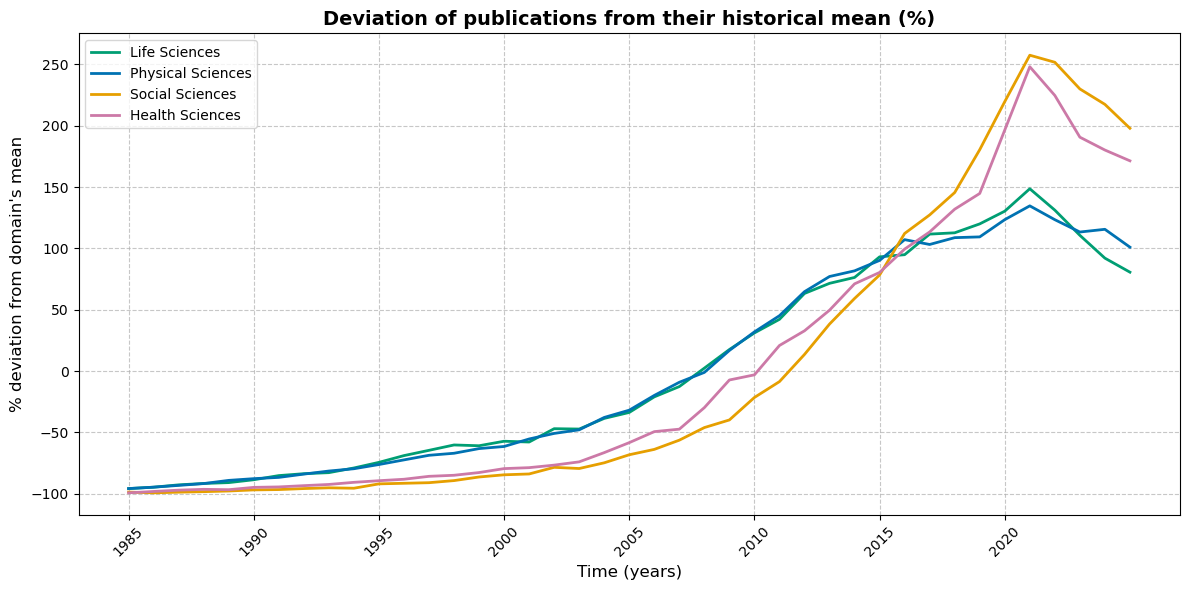

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

# Reorder the domains
ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

# FILTER THE YEARS AFTER 1980 and BEFORE 2025
taula_dominis = taula_dominis[(taula_dominis.index >= 1985) & (taula_dominis.index <= 2025)]

# NORMALIZATION (Any - Mitjana) / Mitjana
# Calculem la mitjana de cada columna
mitjanes = taula_dominis.mean(axis=0)

# Restem la mitjana i dividim per la mitjana, i ho passem a percentatge (* 100)
taula_normalitzada = ((taula_dominis - mitjanes) / mitjanes) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
for i, col in enumerate(taula_normalitzada.columns):
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])
plt.title("Deviation of publications from their historical mean (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% deviation from domain's mean", fontsize=12) 

# Horitzontal axis to 0 --> mean
#plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)
ticks_anys = np.arange(1985,2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/deviation_publications_from_history.png", dpi=300, bbox_inches='tight')

plt.show()

### CONTRIBUCIÓ RELATIVA

NORMALITZACIO: $$Norm = \frac{H-<H>}{<T>}$$

- $H$ --> nombre de publicacions del domini en un determinat any
- $<H>$ --> mitjana de publicacions del domini al llarg dels anys
- $<T>$ --> mitjana de publicacions total al llarg dels anys

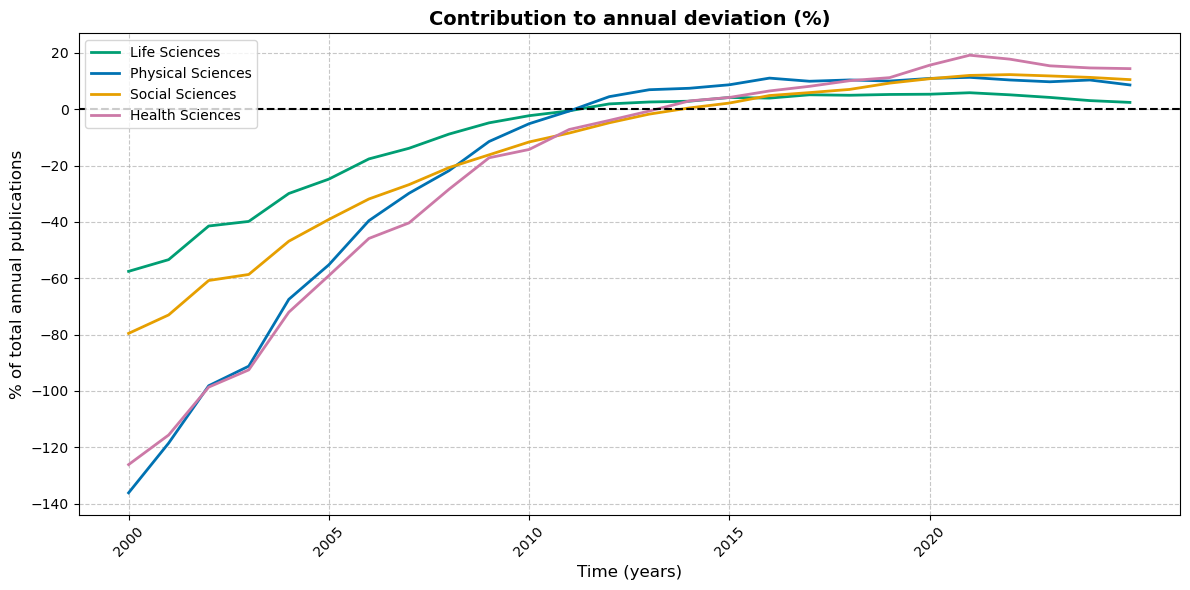

In [92]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

taula_dominis = taula_dominis[(taula_dominis.index >= 2000) & (taula_dominis.index <= 2025)]

# 1. Calculem la mitjana de cada domini
mitjanes = taula_dominis.mean(axis=0)

# 2. Calculem la desviació (Papers de l'any - Mitjana)
desviacio = taula_dominis - mitjanes

# 3. 🆕 NOVA NORMALITZACIÓ: Dividim la desviació pel total de papers d'aquell any
total_anual = taula_dominis.sum(axis=1)
taula_normalitzada = desviacio.div(total_anual, axis=0) * 100

anys = taula_normalitzada.index

# PLOT
plt.figure(figsize=(12, 6))
colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00','Health Sciences': '#CC79A7'}

for i, col in enumerate(taula_normalitzada.columns):
    plt.plot(anys, taula_normalitzada[col], label=col, linewidth=2, color=colors[col])

plt.title("Contribution to annual deviation (%)", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total annual publications", fontsize=12) 

# Línia horitzontal al 0
plt.axhline(0, color='black', linewidth=1.5, linestyle='--')
plt.grid(True, linestyle='--', alpha=0.7)

ticks_anys = np.arange(2000, 2025, 5)
plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/deviation_relative_to_total.png", dpi=300, bbox_inches='tight')

plt.show()

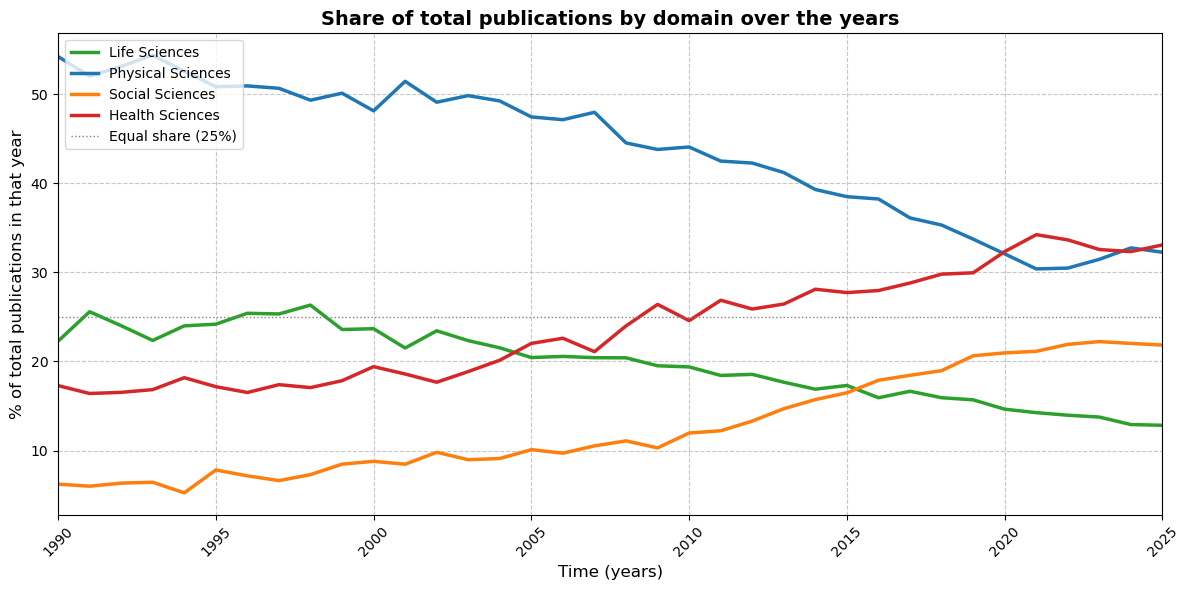

In [49]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

# Reordenem els dominis
ordre_desitjat = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[ordre_desitjat]

# 🆕 NORMALITZACIÓ OPCIÓ 2: Dividir pel total de papers d'aquell any
# .div(..., axis=0) divideix cada fila (any) per la seva suma total
taula_percentatges = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100

# 🆕 FILTRE D'ANYS: DE 1990 A 2025
taula_percentatges = taula_percentatges[(taula_percentatges.index >= 1990) & (taula_percentatges.index <= 2025)]

anys = taula_percentatges.index

# PLOT
plt.figure(figsize=(12, 6))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'] 

for i, col in enumerate(taula_percentatges.columns):
    plt.plot(anys, taula_percentatges[col], label=col, linewidth=2.5, color=colors[i])

plt.title("Share of total publications by domain over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("% of total publications in that year", fontsize=12) 
# Posem una línia horitzontal al 25% (que seria el repartiment perfecte si tots 4 dominis publiquessin igual)
plt.axhline(25, color='gray', linewidth=1, linestyle=':', label='Equal share (25%)')

plt.grid(True, linestyle='--', alpha=0.7)

# 🆕 ELS TICKS DE L'EIX X DE 5 EN 5 COMENÇANT AL 1990
ticks_anys = np.arange(1990, 2026, 5)
plt.xticks(ticks_anys, rotation=45)

# 🆕 FORCEM ELS LÍMITS PERQUÈ NO QUEDIN ESPAIS EN BLANC
plt.xlim(1990, 2025)

# Anys de 5 en 5
#ticks_anys = np.arange(1945, max(anys) + 1, 5)
#plt.xticks(ticks_anys, rotation=45)
plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

### PLOT 4: Publications over the years per domains in different plots (després per Topics)

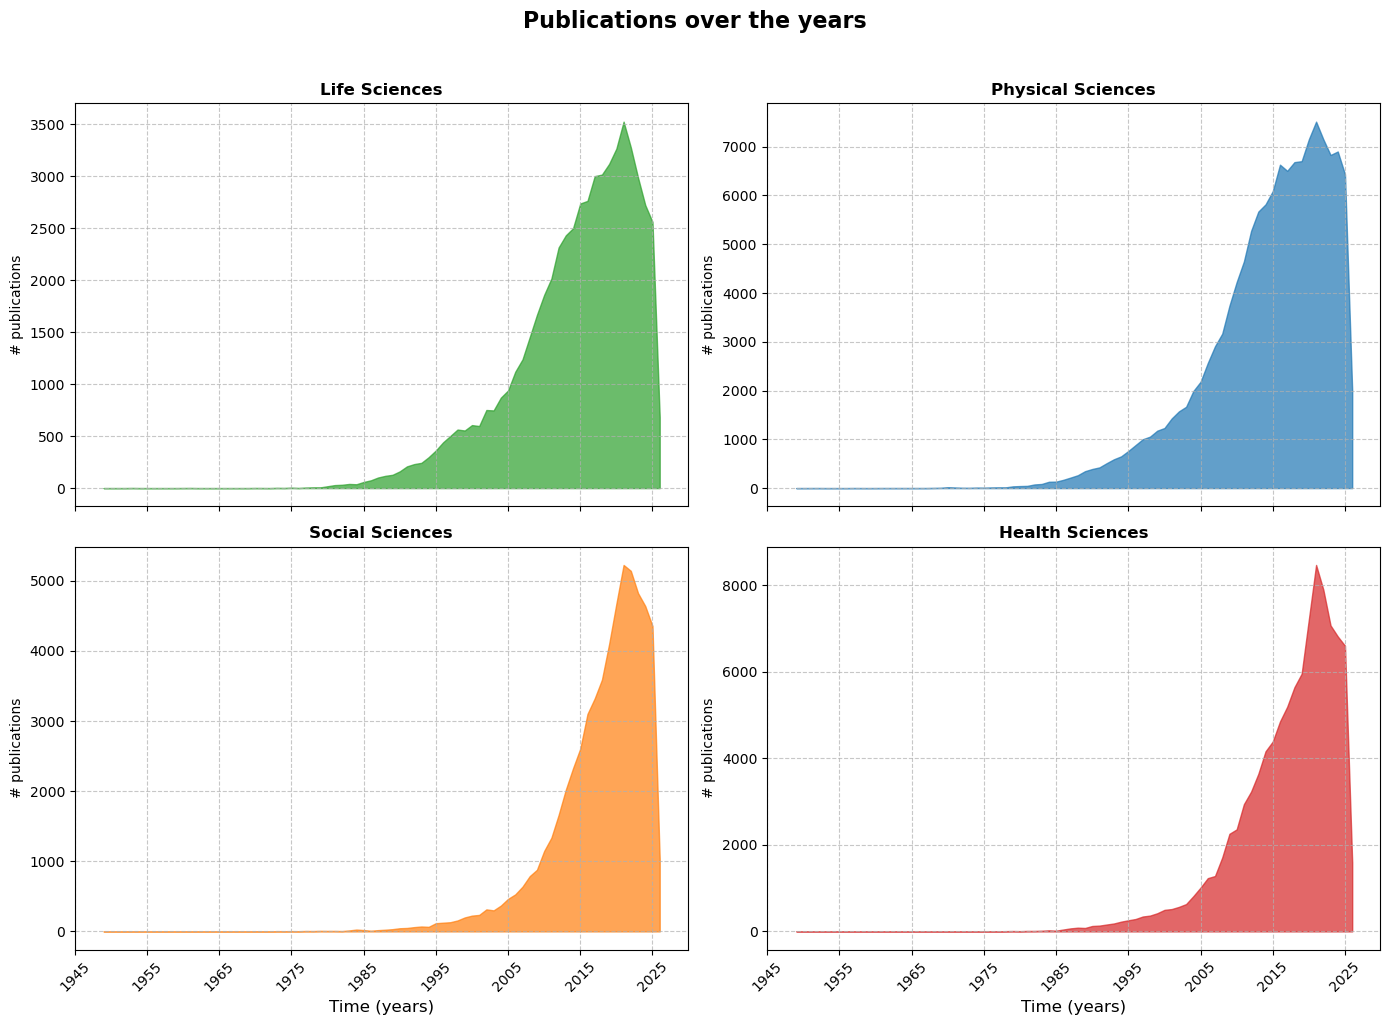

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

anys = taula_dominis.index

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

for i, domini in enumerate(order):
    ax = axes[i]
    ax.fill_between(anys, taula_dominis[domini], color=colors[i], alpha=0.7, label=domini)
    ax.set_title(domini, fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ticks_anys = np.arange(1945, max(anys) + 1, 10)
    ax.set_xticks(ticks_anys)

fig.suptitle("Publications over the years", fontsize=16, fontweight='bold', y=1.02)
axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

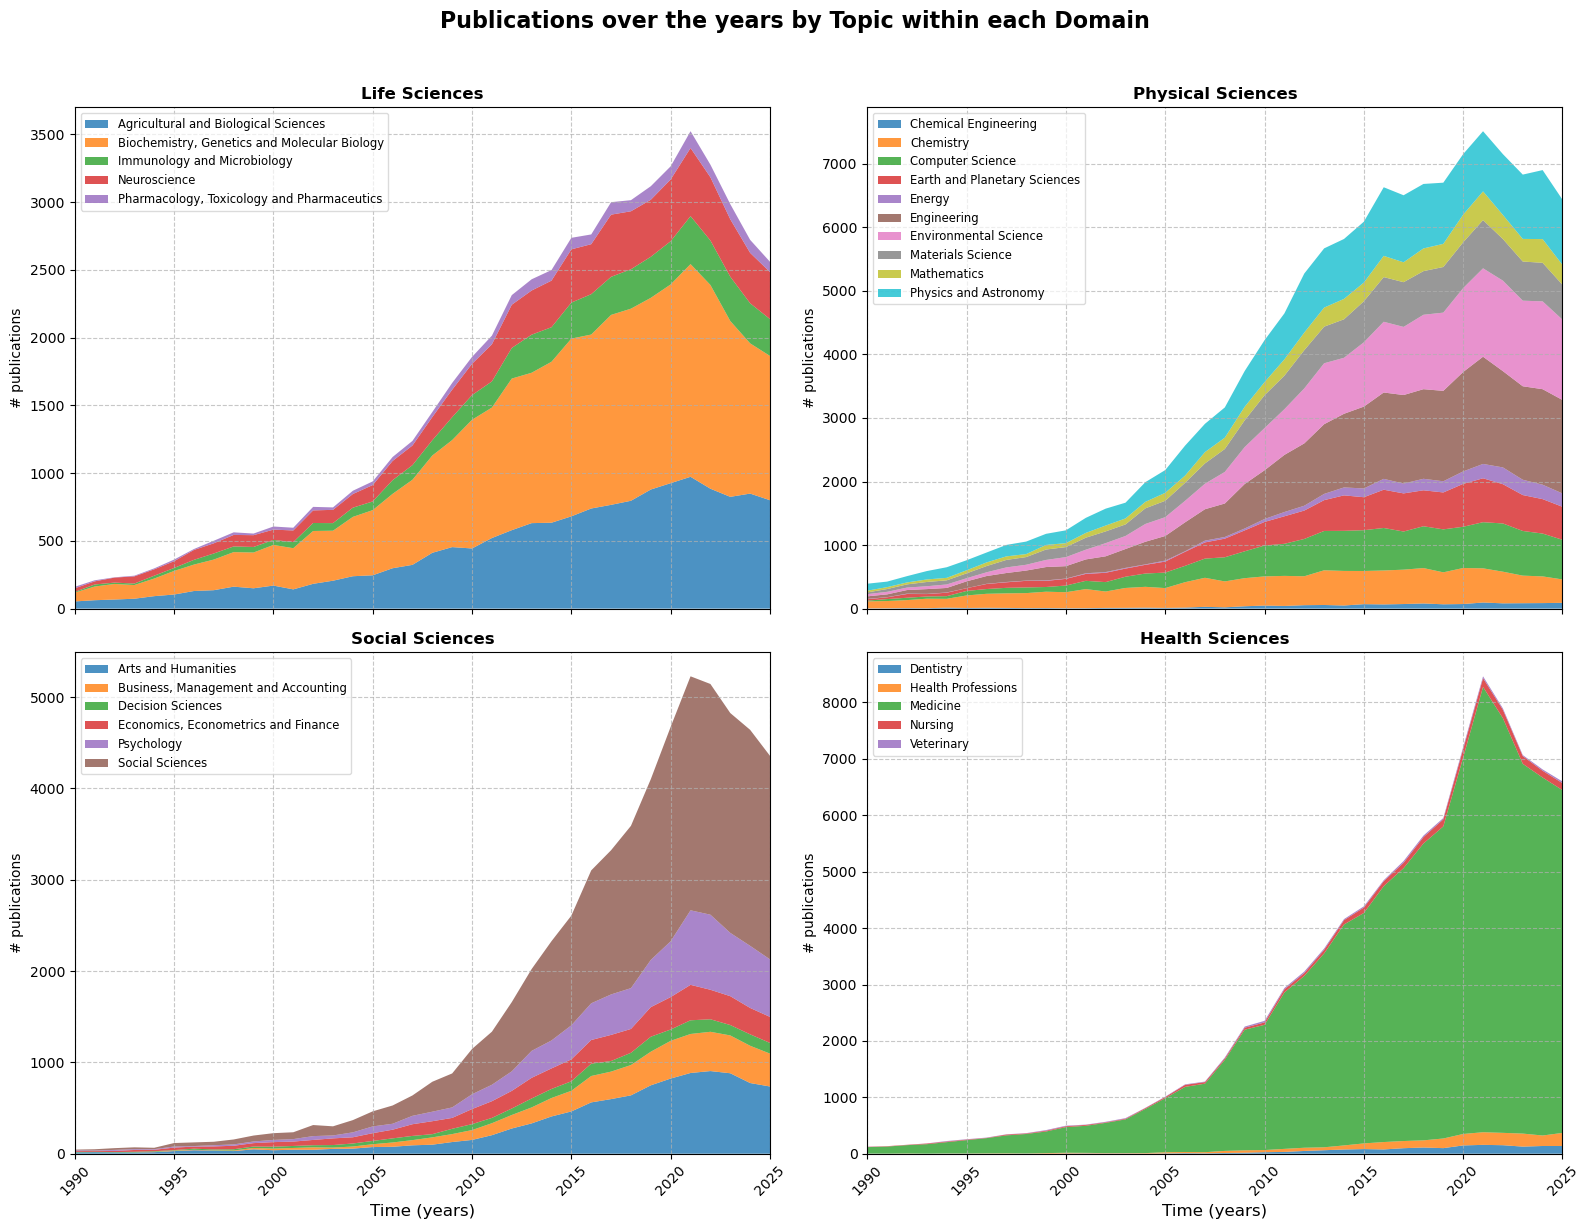

In [39]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name", "field_name"]) # Assegurem que tenim tots dos
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 12), sharex=True)
axes = axes.flatten()

order_domains = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]

for i, domini in enumerate(order_domains):
    ax = axes[i]

    df_dom = df_plots[df_plots["domain_name"] == domini]
    taula_topics = df_dom.groupby(["year", "field_name"]).size().unstack(fill_value=0)

    # If we only want the 5 most famous topics
    #top_topics = taula_topics.sum().nlargest(5).index
    #taula_topics = taula_topics[top_topics]

    taula_topics = taula_topics[(taula_topics.index >= 1990) & (taula_topics.index <= 2025)]
    
    anys = taula_topics.index
    quantitats = [taula_topics[col].values for col in taula_topics.columns]
    etiquetes = taula_topics.columns.tolist()
    ax.stackplot(anys, quantitats, labels=etiquetes, alpha=0.8)
    ax.set_title(f"{domini}", fontsize=12, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.set_ylabel("# publications")
    ax.set_xlim(1990, 2025)
    ax.margins(x=0)
    ticks_anys = np.arange(1990, 2026, 5)
    ax.set_xticks(ticks_anys)
    ax.legend(loc='upper left', fontsize='small', framealpha=0.7)

fig.suptitle("Publications over the years by Topic within each Domain", fontsize=16, fontweight='bold', y=1.02)

axes[2].set_xlabel("Time (years)", fontsize=12)
axes[3].set_xlabel("Time (years)", fontsize=12)

for ax in axes:
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

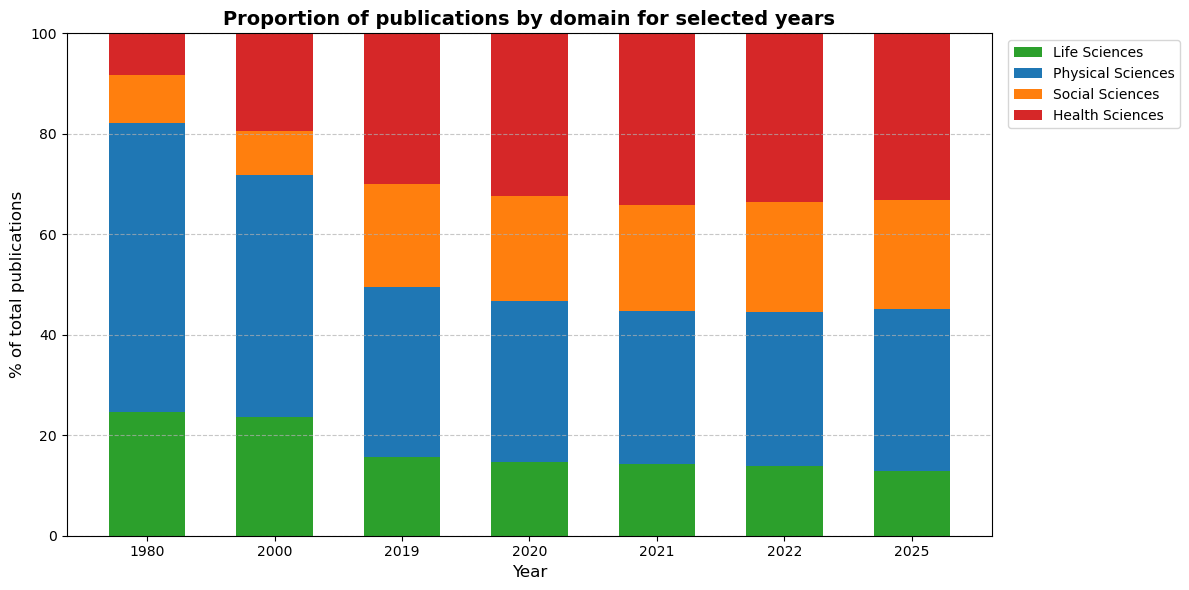

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

# YEARS WE WANT TO SHOW
anys_a_mostrar = [1980, 2000, 2019,2020,2021,2022, 2025]

taula_seleccio = taula_dominis.loc[taula_dominis.index.isin(anys_a_mostrar)]
taula_percent = taula_seleccio.div(taula_seleccio.sum(axis=1), axis=0) * 100

# PLOT
fig, ax = plt.subplots(figsize=(12, 6))
bottom = np.zeros(len(taula_percent))
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']
for i, col in enumerate(taula_percent.columns):
    ax.bar(taula_percent.index.astype(str), taula_percent[col], 
           bottom=bottom, label=col, color=colors[i], width=0.6)
    bottom += taula_percent[col].values
ax.set_title("Proportion of publications by domain for selected years", fontsize=14, fontweight='bold')
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)
ax.set_ylim(0, 100) # Assegurem que l'eix Y vagi de 0 a 100
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1)) # Llegenda fora

plt.tight_layout()
plt.show()

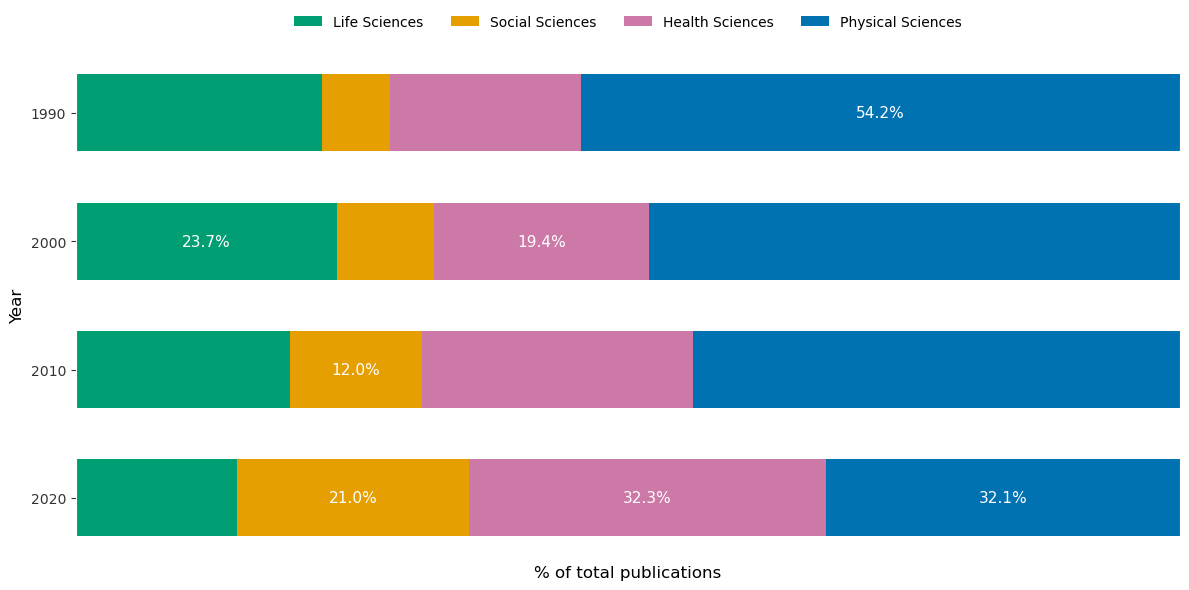

In [ ]:
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)
order = ["Life Sciences", "Social Sciences", "Health Sciences","Physical Sciences"]
taula_dominis = taula_dominis[order]

anys_a_mostrar = [1990, 2000, 2010, 2020]
taula_seleccio = taula_dominis.loc[taula_dominis.index.isin(anys_a_mostrar)]
taula_percent = taula_seleccio.div(taula_seleccio.sum(axis=1), axis=0) * 100

# 3. Configurem els colors
colors = {
    'Life Sciences': '#009E73',
    'Physical Sciences': '#0072B2', 
    'Social Sciences': '#E69F00', 
    'Health Sciences': '#CC79A7'
}
colors_list = [colors[col] for col in taula_percent.columns]

# 4. Creem el gràfic de barres horitzontals
fig, ax = plt.subplots(figsize=(12, 6))

# Per fer les barres horitzontals, l'eix Y és on aniran els anys
anys_str = taula_percent.index.astype(str)
left = np.zeros(len(taula_percent)) # L'equivalent al 'bottom' però per l'esquerra

for i, col in enumerate(taula_percent.columns):
    ax.barh(anys_str, taula_percent[col], 
            left=left, label=col, color=colors_list[i], height=0.6)
    left += taula_percent[col].values

# 5. Estil
#ax.set_title("Proportion of publications by domain for selected years", fontsize=14, fontweight='bold')
ax.set_ylabel("Year", fontsize=12)
ax.set_xlabel("% of total publications", fontsize=12)
ax.set_xlim(0, 100) # L'eix X va de 0 a 100%
ax.grid(axis='x', linestyle='--', alpha=0.7)
ax.invert_yaxis()
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=4, title="", frameon=False)
for spine in ax.spines.values():
    spine.set_color("#FFFFFF") # Gris fosc
ax.tick_params(axis='both', colors='#333333') # Etiquetes dels números en gris
#ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xticks([]) 

etiquetes_demanades = {
    (1990, "Physical Sciences"): "Physical",
    (2000, "Life Sciences"): "Life",
    (2000, "Health Sciences"): "Health",
    (2010, "Social Sciences"): "Social",
    (2020, "Social Sciences"): "Social",
    (2020, "Health Sciences"): "Health",
    (2020, "Physical Sciences"): "Physical"
}

for (any_sel, domini_sel), nom_curt in etiquetes_demanades.items():
    # Comprovem que l'any estigui a la nostra selecció
    if any_sel in taula_percent.index:
        # Calculem la posició X on comença aquesta barra (la suma de les barres a la seva esquerra)
        index_col = taula_percent.columns.get_loc(domini_sel)
        if index_col == 0:
            x_pos = 0
        else:
            x_pos = taula_percent.iloc[list(taula_percent.index).index(any_sel), :index_col].sum()
        
        # Calculem la meitat de l'amplada de la barra per posar el text al mig
        amplada = taula_percent.loc[any_sel, domini_sel]
        x_mig = x_pos + (amplada / 2)
        
        # El valor del percentatge
        valor_text = taula_percent.loc[any_sel, domini_sel]
        
        # Dibuixem el text (en negreta, blanc i al mig de la barra)
        ax.text(x_mig, str(any_sel), f"{valor_text:.1f}%", 
                ha='center', va='center', color='white', fontsize=11)


plt.tight_layout()

# Desem el gràfic
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/horizontal_bars_proportion_by_year.png", dpi=300, bbox_inches='tight')

plt.show()

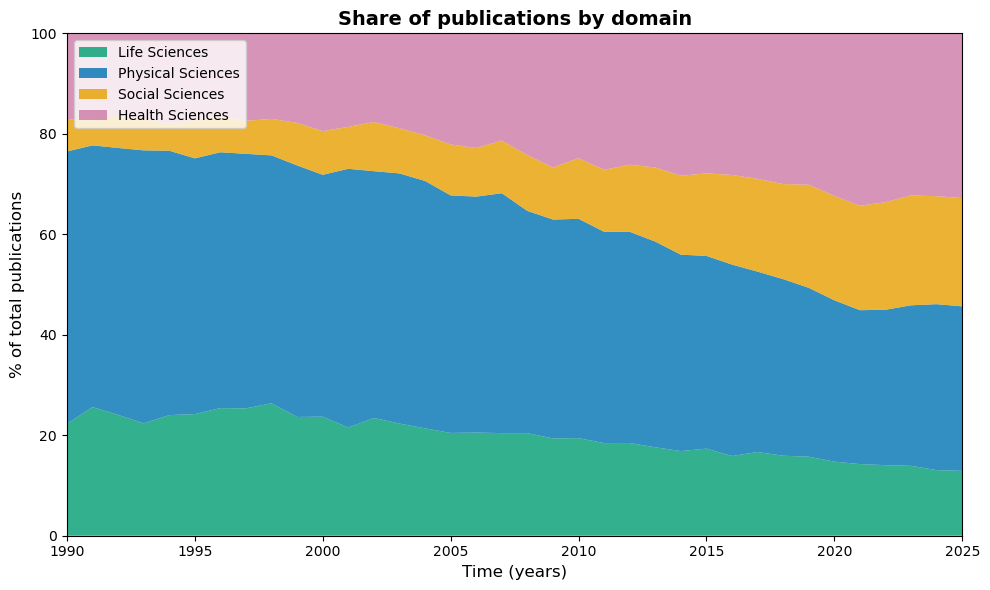

In [16]:
# Continuous domain contributioon to de total
taula_pct = taula_dominis.div(taula_dominis.sum(axis=1), axis=0) * 100
taula_pct = taula_pct.loc[1990:2025, order]  # mateix ordre que l'area chart

fig, ax = plt.subplots(figsize=(10, 6))
ax.stackplot(taula_pct.index, [taula_pct[col].values for col in taula_pct.columns],
             labels=taula_pct.columns.tolist(), colors=[colors[col] for col in taula_pct.columns], alpha=0.8)
ax.set_xlim(1990, 2025)
ax.set_ylim(0, 100)
ax.set_title("Share of publications by domain", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("% of total publications", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{output_dir}/share_by_domain_area.png", dpi=300, bbox_inches="tight")
plt.show()

- Make figures and tables
- Write bullet points/explain as it you think loud

MINI-PAPER:
ordre: title (max 2 lines, 75 caract) --> it should provide some "results"
       abstract
       intro
       methods
       results/discussion
       conclusion

PRESENTACIÓ: 10-15 min. Comencem 10:00.

# COVID

### Data processing

In [106]:
df_papers = pd.read_parquet(EXTERNAL / "papers_cleaned.gencat.parquet")

# Convertim la columna 'date' a format de data real
df_papers['date'] = pd.to_datetime(df_papers['date'])
# Creem les columnes 'year' i 'month'
df_papers['year'] = df_papers['date'].dt.year
df_papers['month'] = df_papers['date'].dt.month

# Eliminates duplicated dois
print("Publicacions AMB duplicats:",len(df_papers))
df_unics = df_papers.drop_duplicates(subset=["doi"]).copy()
print("Publicacions SENSE duplicats:",len(df_unics))

# Load data from fields and works
works = pd.read_parquet(DATA / "external/works.parquet", columns=["doi", "primary_topic_field_id"])
fields = pd.read_parquet(DATA / "external/fields.parquet")

# Eliminates duplicated full rows
print("Works AMB duplicats:",len(works))
works = works.drop_duplicates()
print("Works SENSE duplicats:",len(works))

# Prepare merge
fields["field_id"] = fields["field_id"].astype(str)
field_info = fields.set_index("field_id")[["field_name", "domain_name"]].to_dict(orient="index")

# Creuem els papers únics amb els seus topics
# Com que hi ha papers amb múltiples topics, farem un merge i després un "explode"
df_merged = df_unics.merge(works, on="doi", how="left")

# Cleans names
df_merged["primary_topic_field_id"] = df_merged["primary_topic_field_id"].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# Names mapping
df_merged["topic_name"] = df_merged["primary_topic_field_id"].map(lambda x: field_info.get(x, {}).get("field_name"))
df_merged["domain_name"] = df_merged["primary_topic_field_id"].map(lambda x: field_info.get(x, {}).get("domain_name"))

# Filter data from 2019 to 2022
df_covid = df_merged[(df_merged["year"] >= 2019) & (df_merged["year"] <= 2022)].copy()

# Select only the desired columns
# 'year', 'month', 'doi' i les columnes d'enriquiment (topic_name, domain_name)
columnes_finals = ["year", "month", "doi", "topic_name", "domain_name"]
df_final = df_covid[columnes_finals]

# Save file
output_path = PROCESSED / "all_papers_enriched_covid.parquet"
df_final.to_parquet(output_path, index=False)

print(f"Dimensions: {df_final.shape[0]} files, {df_final.shape[1]} columnes")
print("\nPrimeres files:")
display(df_final.head())

Publicacions AMB duplicats: 1747707
Publicacions SENSE duplicats: 358039
Works AMB duplicats: 348417
Works SENSE duplicats: 348089
Dimensions: 88150 files, 5 columnes

Primeres files:


,year,month,doi,topic_name,domain_name
201902,2019,1,10.1093/sleep/zsy205,Psychology,Social Sciences
201903,2019,1,10.1109/tcomm.2018.2876295,Computer Science,Physical Sciences
201904,2019,1,10.1016/j.jchf.2019.04.022,Medicine,Health Sciences
201905,2019,1,10.1016/j.phrs.2018.11.032,"Biochemistry, Genetics and Molecular Biology",Life Sciences
201906,2019,1,10.1111/jsr.12830,Medicine,Health Sciences


Rows without topics/domains are deleted

In [107]:
df = pd.read_parquet("../data/processed/all_papers_enriched_covid.parquet")

# Count rows
total_files = len(df)
files_amb_topic = df["topic_name"].notna().sum()
files_sense_topic = df["topic_name"].isna().sum()

print(f"Total de files al fitxer: {total_files}")
print(f"Files AMB topic: {files_amb_topic}")
print(f"Files SENSE topic (None): {files_sense_topic}")
print(f"Percentatge de files sense topic: {(files_sense_topic / total_files) * 100:.2f}%")

# Mirem alguns exemples de papers que s'han quedat sense topic
print("\nExemples de files sense topic:")
display(df[df["topic_name"].isna()].head(5))

Total de files al fitxer: 88150
Files AMB topic: 86032
Files SENSE topic (None): 2118
Percentatge de files sense topic: 2.40%

Exemples de files sense topic:


,year,month,doi,topic_name,domain_name
89,2019,1,10.5277/abb-01300-2019-02,None,None
116,2019,1,10.3389/fevo.2019.180,None,None
123,2019,1,10.2436/20.1502.01.3,None,None
166,2019,1,10.13137/1825-5167/28382,None,None
188,2019,1,10.4317/jced.55326.ecollection2019jan,None,None


### Plot _: publicacions 2019-2022

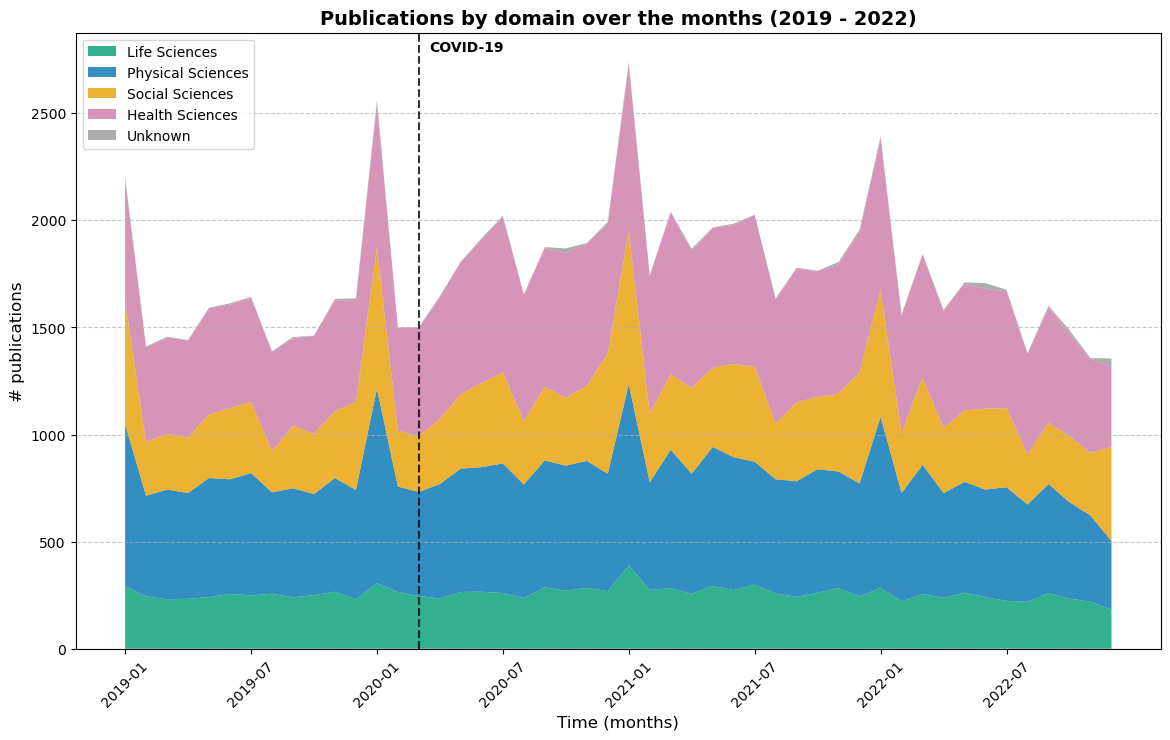

In [ ]:
df = pd.read_parquet("../data/processed/all_papers_enriched_covid_months.parquet")

# New category: UNKNOWN (for topics we dont know)
df["domain_name"] = df["domain_name"].fillna("Unknown")
df["date_month"] = pd.to_datetime(df["year"].astype(str) + "-" + df["month"].astype(str).str.zfill(2))

colors = {'Life Sciences': '#009E73','Physical Sciences': '#0072B2','Social Sciences': '#E69F00',
    'Health Sciences': '#CC79A7','Unknown': '#999999'}

# Only papers with domain assigned (ara tots en tenen, però si vols treure algun altre, ho pots fer aquí)
df_plots = df.copy()

# Eliminate DOI duplicated publications (Opcional, el tens comentat al teu original)
#df_plots = df_plots.drop_duplicates(subset=["doi", "date_month"])

# Create table for the plot: Files = Mesos, Columnes = Dominis, Valors = Nombre de papers
taula_dominis = df_plots.groupby(["date_month", "domain_name"]).size().unstack(fill_value=0)

# Ordenem les columnes (afegint Unknown al final)
order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences", "Unknown"]
# Ens assegurem que només agafem les columnes que existeixen al df per evitar errors
order = [col for col in order if col in taula_dominis.columns]
taula_dominis = taula_dominis[order] 

# NO FILTREM PER ANYS, JA QUE EL FITXER JA NOMÉS TÉ EL 2019-2022

# Creem un índex numèric per a l'eix X perquè el stackplot no accepta dates directament
x_vals = np.arange(len(taula_dominis.index))

# Guardem les etiquetes de text (els mesos) per posar-los després a l'eix
etiquetes_mesos = [d.strftime('%Y-%m') for d in taula_dominis.index]

quantitats = [taula_dominis[col].values for col in taula_dominis.columns]
etiquetes = taula_dominis.columns.tolist()

colors_list = [colors[col] for col in etiquetes]

cumsum = taula_dominis.cumsum(axis=1)

# PLOT
fig = plt.figure(figsize=(14, 8)) 
ax_main = fig.add_subplot(111)   

ax_main.stackplot(x_vals, quantitats, labels=etiquetes, colors=colors_list, alpha=0.8)
ax_main.set_title("Publications by domain over the months (2019 - 2022)", fontsize=14, fontweight='bold')
ax_main.set_xlabel("Time (months)", fontsize=12)
ax_main.set_ylabel("# publications", fontsize=12)
ax_main.grid(axis='y', linestyle='--', alpha=0.7)
ax_main.legend(loc='upper left')

# Show WHEN COVID STARTS (Març de 2020)
# Busquem l'índex on comença el 2020-03
try:
    index_covid = etiquetes_mesos.index('2020-03')
    ax_main.axvline(x=index_covid, color='black', linestyle='--', linewidth=1.5, alpha=0.8)
    ax_main.text(index_covid + 0.5, ax_main.get_ylim()[1]*0.97, 'COVID-19', color='black', fontsize=10, fontweight='bold')
except ValueError:
    pass # Si no troba el mes, no dibuixa la línia



# Personalized axis: we want to show months and years
# Ho posem cada 6 mesos per no saturar
ticks_posicions = np.arange(0, len(x_vals), 6)
ticks_etiquetes = [etiquetes_mesos[i] for i in ticks_posicions]

ax_main.set_xticks(ticks_posicions)
ax_main.set_xticklabels(ticks_etiquetes, rotation=45)

# SAVE PLOT
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/area_chart_publications_by_domain_months.png", dpi=300, bbox_inches='tight')

plt.show()

This figure shows that the data we have don't really have usefull informacion about the papers publication date. This is probably because most of the publications didn't have this information in the Gencat open data web and, therefore, all the unsure dates were automatically classified at the beaggining of each year (january).

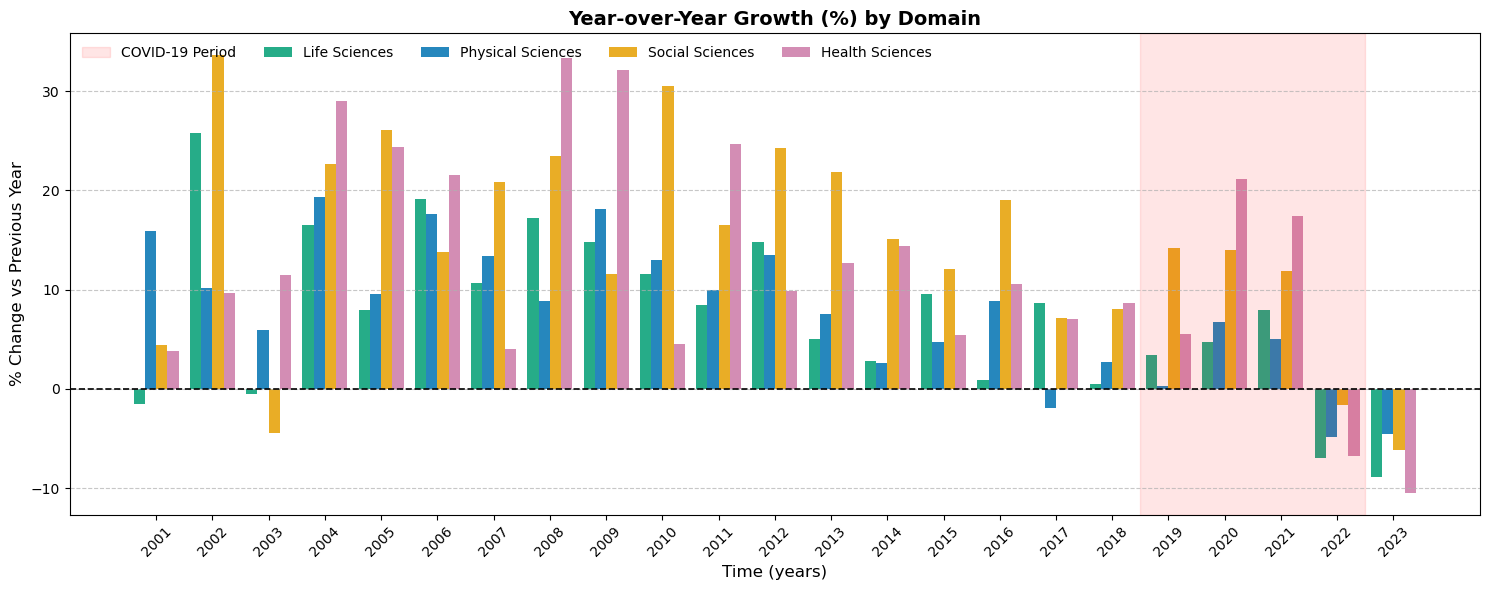

In [65]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# 1. Carreguem i preparem les dades
df = pd.read_parquet("../data/processed/all_publications_enriched.parquet")
df_plots = df.dropna(subset=["domain_name"])
df_plots = df_plots.drop_duplicates(subset=["doi", "year"])

taula_dominis = df_plots.groupby(["year", "domain_name"]).size().unstack(fill_value=0)

order = ["Life Sciences", "Physical Sciences", "Social Sciences", "Health Sciences"]
taula_dominis = taula_dominis[order]

# Filtrem els anys (1985 a 2022 per centrar-nos en la part final de la sèrie)
taula_dominis = taula_dominis[(taula_dominis.index >= 2000) & (taula_dominis.index <= 2023)]

# 🆕 2. CALCULEM EL CREIXEMENT RESPECTE L'ANY ANTERIOR
# pct_change() calcula la diferència percentual respecte a la fila anterior (l'any anterior)
# El multipliquem per 100 per tenir el percentatge
creixement = taula_dominis.pct_change() * 100

# Eliminem el primer any (1985) perquè no té any anterior per comparar
creixement = creixement.dropna()

anys = creixement.index

# 3. Configurem els colors (paleta colorblind-friendly)
colors = {
    'Life Sciences': '#009E73',
    'Physical Sciences': '#0072B2', 
    'Social Sciences': '#E69F00', 
    'Health Sciences': '#CC79A7'
}
colors_list = [colors[col] for col in creixement.columns]

# 4. Creem el gràfic de barres agrupat
fig, ax = plt.subplots(figsize=(15, 6))

# Calculem l'amplada de cada barra (com hi ha 4 barres, les dividim per no tocar-se)
width = 0.2
x = np.arange(len(anys))

# Dibuixem una barra per a cada domini
for i, col in enumerate(creixement.columns):
    # L'offset fa que cada barra es desplaci a la dreta de l'anterior
    offset = (i - 1.5) * width 
    ax.bar(x + offset, creixement[col], width, label=col, color=colors_list[i], alpha=0.85)

# 5. Estil
ax.set_title("Year-over-Year Growth (%) by Domain", fontsize=14, fontweight='bold')
ax.set_ylabel("% Change vs Previous Year", fontsize=12)
ax.set_xlabel("Time (years)", fontsize=12)

# Posem els anys a l'eix X
ax.set_xticks(x)
ax.set_xticklabels(anys.astype(str), rotation=45)

# Línia del 0% per veure els positius i negatius
ax.axhline(0, color='black', linewidth=1.2, linestyle='--')

# 🆕 AFEGIM UNA OMBRA PER DESTACAR EL PERÍODE DEL COVID (2019 - 2022)
# Busquem les posicions dels anys 2019 a 2022 a l'eix X
idx_2019 = list(anys).index(2019)
idx_2022 = list(anys).index(2022)
ax.axvspan(idx_2019 - 0.5, idx_2022 + 0.5, color='red', alpha=0.1, label='COVID-19 Period')

# Llegenda
ax.legend(loc='upper left', ncol=5, frameon=False)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

# 6. Guardem el gràfic
output_dir = "../plots/alba"
os.makedirs(output_dir, exist_ok=True)
plt.savefig(f"{output_dir}/yearly_growth_by_domain.png", dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# %% 2. Canvi de pendent pre-COVID: dos ajustos log-log a cada costat d'un any de tall
# Es tria el tall que minimitza l'error total (descriptiu, no és un test estadístic)
dades_pre = taula_total.loc[1990:2019]

for col in dades_pre.columns:
    millor = [np.inf, None, None, None]  # error, any de tall, alpha abans, alpha després
    for tall in range(2000, 2015):
        error, alphes = 0, []
        for tros in (dades_pre.loc[:tall, col], dades_pre.loc[tall:, col]):
            x = np.log10(tros.index.values)
            y = np.log10(tros.values)
            m, b = np.polyfit(x, y, 1)
            error += np.sum((y - (m * x + b)) ** 2)
            alphes.append(m)
        if error < millor[0]:
            millor = [error, tall, alphes[0], alphes[1]]
    print(f"{col:18s} tall = {millor[1]}  alpha abans = {millor[2]:.0f}  alpha després = {millor[3]:.0f}")


Life Sciences      tall = 2012  alpha abans = 223  alpha després = 90
Physical Sciences  tall = 2013  alpha abans = 228  alpha després = 61
Social Sciences    tall = 2011  alpha abans = 319  alpha després = 268
Health Sciences    tall = 2008  alpha abans = 278  alpha després = 217
Total              tall = 2013  alpha abans = 250  alpha després = 124


                   pic_year  pic_%_over_base  2025_%_over_base
domain_name                                                   
Life Sciences          2021             14.1             -17.3
Physical Sciences      2021             13.1              -3.2
Social Sciences        2021             38.3              14.8
Health Sciences        2021             48.6              13.7
Total                  2021             28.7               3.1


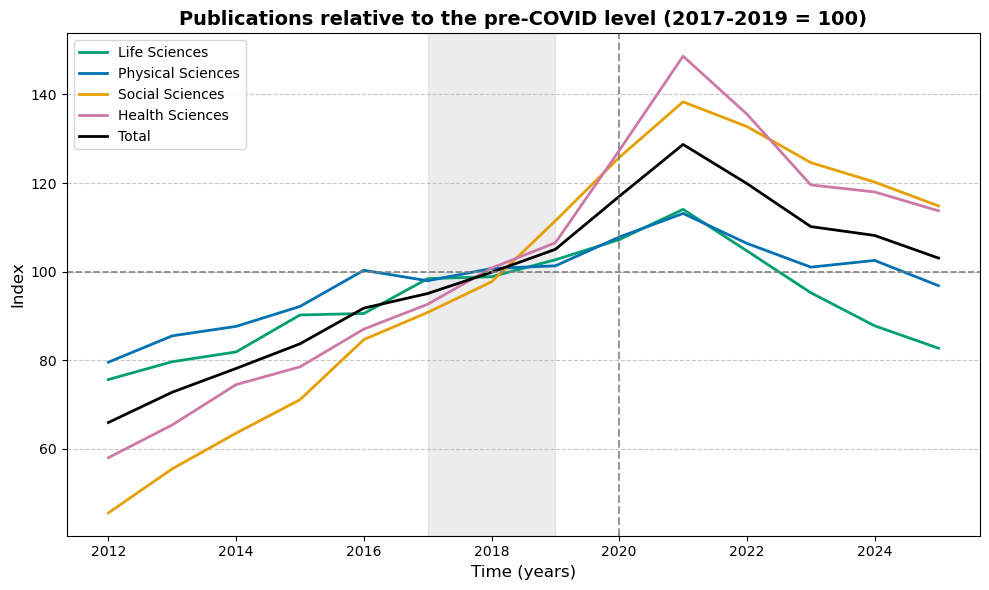

In [ ]:
# COVID PEAK: level with respect to the base pre-COVID (mitjana 2017-2019 = 100)
base = taula_total.loc[2017:2019].mean()
taula_index = taula_total.loc[2012:2025] / base * 100

pic_any = taula_index.loc[2020:].idxmax()
pic_valor = taula_index.loc[2020:].max() - 100
valor_2025 = taula_index.loc[2025] - 100
print(pd.DataFrame({"pic_year": pic_any, "pic_%_over_base": pic_valor.round(1), "2025_%_over_base": valor_2025.round(1)}))

fig, ax = plt.subplots(figsize=(10, 6))
for col in taula_index.columns:
    ax.plot(taula_index.index, taula_index[col], color=colors_tot[col], linewidth=2, label=col)
ax.axhline(y=100, color="gray", linestyle="--", linewidth=1.2)
ax.axvspan(2017, 2019, color="gray", alpha=0.15)  # període base
ax.axvline(x=2020, color="gray", linestyle="--", linewidth=1.5, alpha=0.8)
ax.set_title("Publications relative to the pre-COVID level (2017-2019 = 100)", fontsize=14, fontweight="bold")
ax.set_xlabel("Time (years)", fontsize=12)
ax.set_ylabel("Index", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.7)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(f"{output_dir}/covid_index_by_domain.png", dpi=300, bbox_inches="tight")
plt.show()